In [146]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

In [147]:
df = pd.read_csv('Desktop\K-means dataset.csv')
df.head()


,CustomerID,Age,Annual_Income_USD,Spending_Score,Purchase_Frequency_PerYear,Avg_Cart_Value_USD
0,1,42,102300,100,27,155.6
1,2,47,89900,53,6,145.2
2,3,67,42200,24,6,47.7
3,4,22,29100,65,25,32.2
4,5,62,35300,21,5,44.0


In [148]:
df = df.apply(pd.to_numeric, errors='coerce')
df = df.dropna(subset=['Age', 'Annual_Income_USD', 'Spending_Score', 'Purchase_Frequency_PerYear', 'Avg_Cart_Value_USD'])
df = df.reset_index(drop=True)

In [149]:
features = [
    'Age',
    'Annual_Income_USD',
    'Spending_Score',
    'Purchase_Frequency_PerYear',
    'Avg_Cart_Value_USD'
]

In [150]:
x = df[features]
x_scaled = StandardScaler().fit_transform(x)
x_scaled

array([[-0.01217245,  1.04633895,  1.57549915,  1.0375306 ,  0.948324  ],
       [ 0.33326207,  0.71659592, -0.08904555, -0.92452341,  0.796526  ],
       [ 1.71500019, -0.55185104, -1.11610505, -0.92452341, -0.62658034],
       ...,
       [-1.25573676, -0.7247002 ,  0.69010303,  0.10321917, -0.84406018],
       [ 0.6096097 ,  0.95326632,  0.30052874, -0.83109227, -0.10842367],
       [ 0.26417517,  1.290987  , -1.00985751, -0.45736769,  0.51482392]],
      shape=(420, 5))

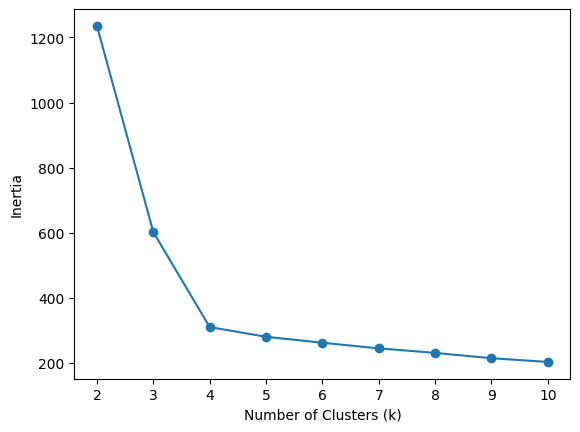

In [151]:
inertias = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=12,
        random_state=42
    )
    kmeans.fit(x_scaled)
    inertias.append(kmeans.inertia_)

plt.plot(range(2, 11), inertias, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.show()

In [152]:
clus_num = 4
k_means = KMeans(init = 'k-means++', n_clusters = clus_num, n_init=12, random_state=42)
k_means.fit(x_scaled)
labels = k_means.labels_
labels

array([3, 1, 2, 0, 2, 3, 3, 0, 0, 1, 2, 2, 1, 2, 2, 0, 3, 2, 3, 0, 2, 3,
       1, 3, 0, 3, 1, 2, 3, 3, 2, 1, 2, 2, 1, 1, 0, 1, 3, 3, 2, 3, 2, 0,
       0, 1, 3, 0, 3, 1, 2, 1, 3, 2, 2, 2, 1, 0, 3, 2, 0, 0, 2, 3, 0, 0,
       0, 2, 2, 2, 0, 0, 0, 1, 3, 1, 2, 1, 3, 2, 3, 3, 0, 1, 2, 2, 1, 0,
       0, 1, 0, 0, 1, 2, 0, 0, 1, 3, 0, 2, 0, 3, 1, 2, 1, 3, 0, 2, 1, 2,
       3, 1, 1, 3, 0, 2, 3, 2, 2, 0, 1, 2, 0, 0, 1, 0, 3, 3, 3, 0, 0, 2,
       2, 0, 1, 0, 1, 2, 0, 1, 0, 3, 1, 0, 1, 1, 0, 1, 3, 2, 1, 1, 2, 2,
       0, 2, 0, 0, 3, 2, 3, 0, 1, 2, 2, 3, 0, 2, 1, 1, 1, 3, 3, 3, 0, 1,
       0, 1, 1, 3, 2, 0, 2, 2, 3, 2, 3, 2, 0, 3, 3, 2, 1, 2, 0, 2, 1, 3,
       2, 2, 3, 3, 0, 2, 0, 2, 3, 0, 0, 0, 1, 3, 0, 1, 2, 2, 1, 1, 2, 1,
       0, 0, 2, 2, 1, 3, 1, 1, 0, 2, 3, 2, 1, 1, 3, 2, 3, 0, 1, 0, 2, 2,
       0, 1, 0, 0, 2, 3, 3, 3, 3, 1, 0, 1, 2, 0, 0, 3, 2, 0, 2, 3, 1, 0,
       1, 2, 1, 0, 2, 0, 3, 1, 2, 1, 3, 1, 2, 2, 1, 0, 3, 3, 2, 0, 2, 2,
       0, 2, 1, 0, 0, 0, 0, 3, 2, 0, 1, 2, 3, 3, 1,

In [153]:
df["Clus_km"] = labels
df.head(5)

,CustomerID,Age,Annual_Income_USD,Spending_Score,Purchase_Frequency_PerYear,Avg_Cart_Value_USD,Clus_km
0,1,42,102300,100,27,155.6,3
1,2,47,89900,53,6,145.2,1
2,3,67,42200,24,6,47.7,2
3,4,22,29100,65,25,32.2,0
4,5,62,35300,21,5,44.0,2


In [154]:
df.groupby('Clus_km')[features].mean()

,Age,Annual_Income_USD,Spending_Score,Purchase_Frequency_PerYear,Avg_Cart_Value_USD
Clus_km,,,,,
0,23.663636,28512.727273,78.563636,22.172727,33.120000
1,45.188119,94068.316832,46.861386,10.643564,125.269307
2,57.350000,33419.166667,19.658333,4.158333,39.255833
3,41.179775,110026.966292,85.191011,29.921348,191.660674


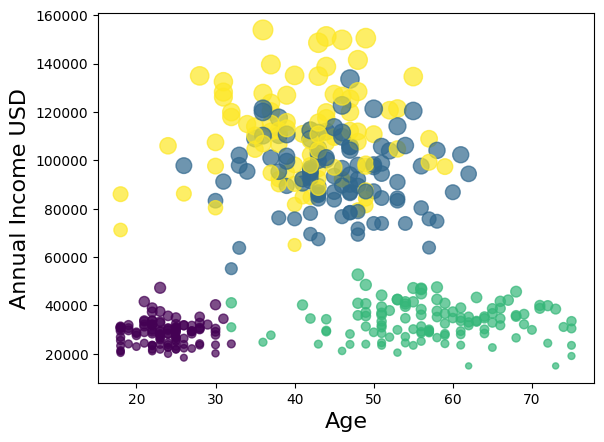

In [155]:
area = x['Annual_Income_USD'] / x['Annual_Income_USD'].max() * 200
plt.scatter(
    x['Age'],
    x['Annual_Income_USD'],
    s=area,
    c=labels.astype(float),
    alpha=0.7
)
plt.xlabel('Age', fontsize=16)
plt.ylabel('Annual Income USD', fontsize=16)
plt.show()

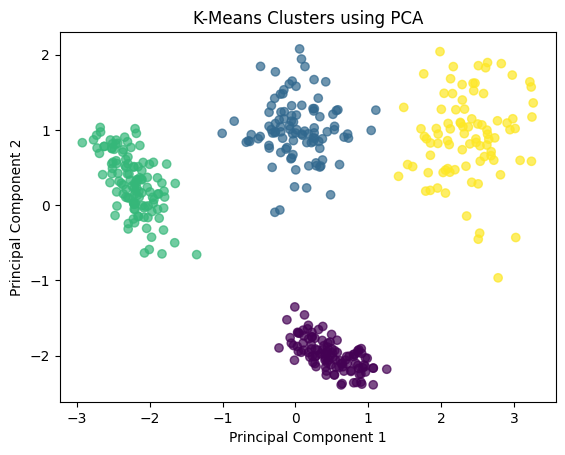

In [156]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(x_scaled)

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels,
    alpha=0.7
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('K-Means Clusters using PCA')
plt.show()

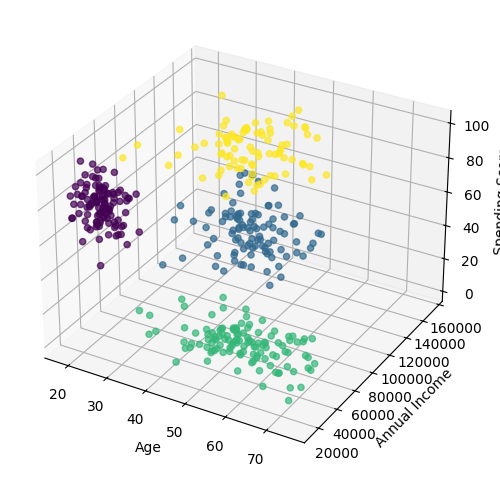

In [158]:
fig = plt.figure(figsize=(8, 6))

ax = fig.add_subplot(
    111,
    projection='3d'
)

ax.set_xlabel('Age')
ax.set_ylabel('Annual Income')
ax.set_zlabel('Spending Score')

ax.scatter(
    x['Age'],
    x['Annual_Income_USD'],
    x['Spending_Score'],
    c=labels,
    alpha=0.7
)

plt.show()